        # Lesson 7.7 · Deep-Learning Forecasting: A First Look
        ### Windows, RNN, LSTM, GRU and a small Transformer: in PyTorch

        | | |
        |---|---|
        | ⏱️ **Time** | about 100 minutes |
        | 📚 **Before you start** | Lessons 7.1 – 7.6. No deep-learning background needed: this is a guided tour; Phase 8 builds the foundations step by step. |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Shape sequence data as **(batch, time, features)** windows
- Describe what **RNN, LSTM, GRU and Transformer** layers do for a forecaster
- Train four sequence models with **chronological** train / validation / test splits and an **embargo**
- Judge them honestly against **naive and Ridge** baselines, and understand why deep learning is *not* automatically better

> 🌾 **The story so far.** The data scientist at the cooperative says: *"Everyone says LSTMs are best for time series."* We'll test the claim on our own data rather than believe it.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py

import torch, torch.nn as nn
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
torch.set_num_threads(1)
warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## 1 · Why sequence models exist

Our ML models in Lesson 7.6 looked at *hand-crafted summaries* of the past (momentum, volatility…). A **sequence model** instead reads the raw window
of the last *L* weeks **in order** and learns its own summary.

| Architecture | One-sentence idea |
|---|---|
| **RNN** | read the sequence one step at a time, carrying a *hidden state* (a memory vector) forward |
| **LSTM** | an RNN with **gates** that decide what to *forget*, *write* and *reveal*: it can remember across long spans |
| **GRU** | a leaner LSTM with two gates (*update*, *reset*): fewer parameters, often similar accuracy |
| **Transformer** | no recurrence: every time step **attends** to every other step and learns which ones matter |

> 🧭 Gates, attention and back-propagation-through-time are dissected in **Phase 8, Lessons 8.8 and 8.9**. Today we treat them as powerful black boxes and observe how they *behave*.

### Data shape: the single most important thing to get right
PyTorch sequence layers (with `batch_first=True`) expect

$$\text{input}: (\text{batch},\; \text{time steps},\; \text{features})$$

e.g. `(32, 52, 4)` = 32 samples, each a 52-week window with 4 features per week.

## 2 · Preparing the experiment

**Task.** At each weekly origin *t* predict the cumulative log-change of price for horizons **1…8 weeks**: a vector of 8 numbers (multi-output, direct).
**Input window.** The last 52 weeks of: weekly log-return, calendar sin/cos, 9-week rainfall (4 features per week).
**Scaling.** Standardise using **training-period statistics only**.
**Splits.** Chronological, with an **embargo** of 8 weeks between blocks (targets look 8 weeks ahead, so without a gap the training targets would overlap the validation inputs).

In [2]:
y = ag.price_series("tomato", "Central", "W")
ly = np.log(y)
rain9 = ag.load_weather().set_index("date")["rainfall_mm"].resample("W").sum().reindex(y.index).rolling(9, min_periods=1).sum()
EXOG = pd.DataFrame({"rain_9w": rain9})

L, H = 52, 8
doy = y.index.dayofyear.to_numpy()
F_raw = np.column_stack([ly.diff().fillna(0).to_numpy(), np.sin(2*np.pi*doy/365.25), np.cos(2*np.pi*doy/365.25), rain9.to_numpy()])
Y_raw = np.column_stack([(ly.shift(-k) - ly).to_numpy() for k in range(1, H + 1)])        # NaN for the last H origins

origins = np.arange(L, len(y) - H)                      # origin positions with a full window and a full target
TRAIN_END, VAL = 320, (329, 370)                        # 8-week embargo between blocks
TEST = (379, origins[-1])
tr_o = origins[origins <= TRAIN_END]
va_o = origins[(origins >= VAL[0]) & (origins <= VAL[1])]
te_o = origins[(origins >= TEST[0])]
print(f"origins  train: {len(tr_o)} | validation: {len(va_o)} | test: {len(te_o)}")

# standardise with TRAIN statistics only
f_mu, f_sd = F_raw[:TRAIN_END + 1].mean(0), F_raw[:TRAIN_END + 1].std(0)
y_mu, y_sd = Y_raw[tr_o].mean(0), Y_raw[tr_o].std(0)
F = (F_raw - f_mu) / f_sd
Y = (Y_raw - y_mu) / y_sd

def make_seq_windows(F, Y, origins, lookback):
    X = np.stack([F[t - lookback + 1: t + 1] for t in origins])       # window ENDS at the origin (inclusive)
    return torch.tensor(X, dtype=torch.float32), torch.tensor(Y[origins], dtype=torch.float32)

Xtr, Ytr = make_seq_windows(F, Y, tr_o, L)
Xva, Yva = make_seq_windows(F, Y, va_o, L)
Xte, Yte = make_seq_windows(F, Y, te_o, L)
print("Xtr shape (batch, time, features):", tuple(Xtr.shape), "| Ytr:", tuple(Ytr.shape))

origins  train: 269 | validation: 42 | test: 136


Xtr shape (batch, time, features): (269, 52, 4) | Ytr: (269, 8)


---
### 🧩 Exercise 1: Windowing by hand  ⭐

Write `my_windows(arr, lookback, horizon)` that turns a 1-D array into `X` of shape `(n, lookback)` and `y` of shape `(n, horizon)`,
where `X[i] = arr[i : i+lookback]` and `y[i] = arr[i+lookback : i+lookback+horizon]`, for as many *complete* windows as fit.
Test it on `np.arange(10)` with `lookback=3, horizon=2` → store in `Xw, yw`.

<details><summary>💡 Hint 1: gentle nudge</summary>

The number of windows is `len(arr) - lookback - horizon + 1`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

A list comprehension over `i in range(n)` that slices `arr[i:i+lookback]` and `arr[i+lookback:i+lookback+horizon]`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Wrap with `np.array(...)`. Compare with `ag.make_windows` when finished.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
def my_windows(arr, lookback, horizon):
    arr = np.asarray(arr, float)
    return None, None

Xw, yw = my_windows(np.arange(10), 3, 2)

In [ ]:
try:
    Xr, yr = ag.make_windows(np.arange(10), 3, 2)
    ag.check("shapes are (6, 3) and (6, 2)", Xw is not None and Xw.shape == (6, 3) and yw.shape == (6, 2))
    ag.check("matches ag.make_windows", Xw is not None and np.allclose(Xw, Xr) and np.allclose(yw, yr))
    ag.check("the last window ends right before its targets (no overlap)", Xw is not None and Xw[-1][-1] + 1 == yw[-1][0])
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 3 · One model class, four architectures

In [5]:
class SeqForecaster(nn.Module):
    """Reads a (batch, time, features) window and outputs H forecasts. kind in {rnn, lstm, gru, transformer}."""
    def __init__(self, kind, n_feat=4, hidden=32, horizon=8, lookback=52, dropout=0.1):
        super().__init__()
        self.kind = kind
        if kind in ("rnn", "lstm", "gru"):
            Rec = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[kind]
            self.enc = Rec(n_feat, hidden, batch_first=True)
        else:                                                     # a tiny Transformer encoder
            self.inp = nn.Linear(n_feat, hidden)
            self.pos = nn.Parameter(torch.randn(1, lookback, hidden) * 0.02)      # learned positional embedding
            layer = nn.TransformerEncoderLayer(hidden, nhead=4, dim_feedforward=64, dropout=dropout, batch_first=True)
            self.enc = nn.TransformerEncoder(layer, num_layers=2)
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, horizon))

    def forward(self, x):
        if self.kind == "transformer":
            z = self.enc(self.inp(x) + self.pos)
            summary = z.mean(dim=1)                               # average over time
        else:
            out, _ = self.enc(x)
            summary = out[:, -1]                                  # hidden state after reading the last week
        return self.head(summary)

for k in ("rnn", "lstm", "gru", "transformer"):
    net = SeqForecaster(k)
    print(f"{k:12s} parameters: {sum(p.numel() for p in net.parameters()):6,d}   output shape: {tuple(net(Xtr[:5]).shape)}")

rnn          parameters:  1,480   output shape: (5, 8)


lstm         parameters:  5,128   output shape: (5, 8)
gru          parameters:  3,912   output shape: (5, 8)


transformer  parameters: 19,176   output shape: (5, 8)


---
### 🧩 Exercise 2: Count the parameters  ⭐⭐

PyTorch's recurrent layers have, per gate-group, an input weight `(h×d)`, a recurrent weight `(h×h)` and **two** bias vectors `(h)` each.
An RNN has 1 group, a GRU has 3, an LSTM has 4. For input size `d = 4` and hidden size `h = 32`:
1. Compute the counts by **formula** in dict `formula` (`{"rnn":…, "gru":…, "lstm":…}`).
2. Compute them by **counting** the parameters of real `nn.RNN/nn.GRU/nn.LSTM(4, 32)` layers in dict `counted`.

<details><summary>💡 Hint 1: gentle nudge</summary>

One group has `h*d + h*h + 2*h` parameters.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`formula = {'rnn': g, 'gru': 3*g, 'lstm': 4*g}` where `g = 32*4 + 32*32 + 2*32`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`sum(p.numel() for p in layer.parameters())` counts a layer's parameters.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
d, h = 4, 32
formula = {}
counted = {}

In [ ]:
try:
    ag.check("formula has the three architectures", set(formula) == {"rnn", "gru", "lstm"})
    ag.check("formula equals the real counts", formula == counted and counted.get("lstm") == 4864,
             "LSTM = 4 x (h*d + h*h + 2h); GRU = 3 x ...; RNN = 1 x ...")
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

## 4 · A training loop (you'll write your own in Phase 8)
Adam optimiser, MSE loss, mini-batches, and **early stopping**: keep the weights from the epoch with the best *validation* loss.

In [8]:
def train(kind, seed=0, epochs=120, lr=2e-3, batch=32, patience=15, hidden=32, verbose=False):
    torch.manual_seed(seed)
    net = SeqForecaster(kind, hidden=hidden)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-3)
    lossf = nn.MSELoss()
    best, best_state, wait, hist = np.inf, None, 0, []
    for ep in range(epochs):
        net.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch):
            idx = perm[i:i + batch]
            opt.zero_grad(); loss = lossf(net(Xtr[idx]), Ytr[idx]); loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
        net.eval()
        with torch.no_grad():
            tr_l, va_l = lossf(net(Xtr), Ytr).item(), lossf(net(Xva), Yva).item()
        hist.append((tr_l, va_l))
        if va_l < best - 1e-4:
            best, best_state, wait = va_l, {k: v.clone() for k, v in net.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience: break
    net.load_state_dict(best_state); net.eval()
    return net, np.array(hist)

def to_prices(pred_std, origins_pos):
    """standardised multi-horizon predictions -> price forecasts, shape (n_origins, H)"""
    change = pred_std * y_sd + y_mu
    return y.to_numpy()[origins_pos][:, None] * np.exp(change)

nets, hists = {}, {}
for kind in ("rnn", "lstm", "gru", "transformer"):
    nets[kind], hists[kind] = train(kind)
    print(f"{kind:12s} trained for {len(hists[kind])} epochs | best validation loss {hists[kind][:, 1].min():.3f}")

rnn          trained for 77 epochs | best validation loss 0.352


lstm         trained for 60 epochs | best validation loss 0.381


gru          trained for 68 epochs | best validation loss 0.329


transformer  trained for 29 epochs | best validation loss 0.453


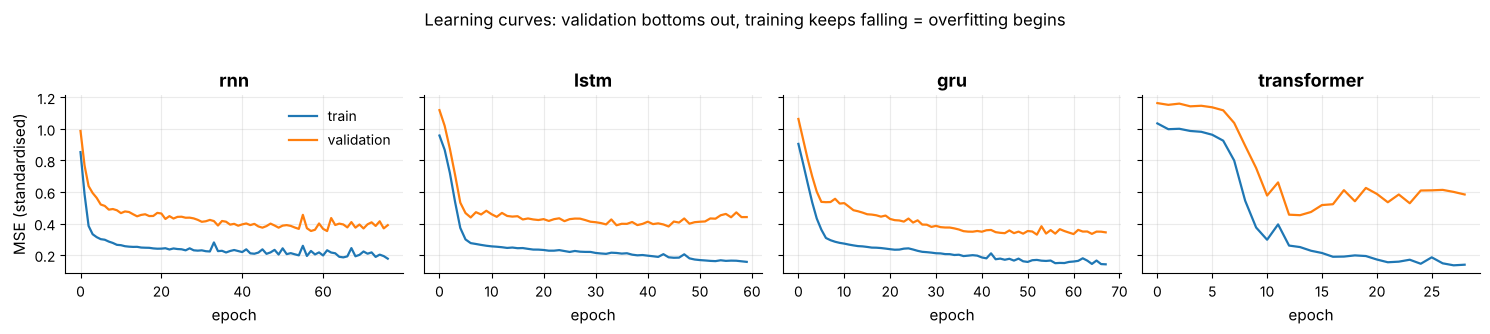

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, (k, h) in zip(axes, hists.items()):
    ax.plot(h[:, 0], label="train"); ax.plot(h[:, 1], label="validation"); ax.set_title(k); ax.set_xlabel("epoch")
axes[0].set_ylabel("MSE (standardised)"); axes[0].legend(); plt.suptitle("Learning curves: validation bottoms out, training keeps falling = overfitting begins", y=1.03); plt.tight_layout(); plt.show()

Look at the gap between the curves: the models **memorise** the ~270 training windows quickly. With so little data that is the central challenge of deep learning on a single series, which is why we use early stopping, weight decay, dropout and small networks.

## 5 · The honest test
Same test origins for everyone. Baselines: **naive** and the **Ridge** direct model from Lesson 7.6 (trained once on the same training origins).

In [10]:
actual = y.to_numpy()[te_o[:, None] + np.arange(1, H + 1)]                # true prices at h = 1..8, shape (n_test, H)
preds = {"naive": np.repeat(y.to_numpy()[te_o][:, None], H, axis=1)}

# Ridge, one model per horizon, trained once on origins <= TRAIN_END
ridge = np.zeros((len(te_o), H))
for k in range(1, H + 1):
    tab = ag.make_origin_table(y, k, EXOG)
    fit = tab.iloc[:TRAIN_END + 1].dropna(); fit = fit[fit.index <= y.index[TRAIN_END]]
    m = make_pipeline(StandardScaler(), Ridge(10)).fit(fit.drop(columns="target"), fit["target"])
    ridge[:, k - 1] = y.to_numpy()[te_o] * np.exp(m.predict(tab.drop(columns="target").iloc[te_o]))
preds["Ridge"] = ridge

for kind, net in nets.items():
    with torch.no_grad():
        preds[kind.upper() if kind != "transformer" else "Transformer"] = to_prices(net(Xte).numpy(), te_o)

rows = {name: {f"h={h}": ag.mae(actual[:, h-1], p[:, h-1]) for h in (1, 4, 8)} | {"avg h=1..8": ag.mae(actual, p)} for name, p in preds.items()}
board = pd.DataFrame(rows).T.round(2).sort_values("avg h=1..8"); board

,h=1,h=4,h=8,avg h=1..8
Ridge,4.30,8.85,14.83,9.60
LSTM,4.53,12.08,18.63,12.30
RNN,4.57,11.37,20.26,12.66
Transformer,4.64,13.55,25.06,14.88
GRU,5.37,16.72,25.15,16.76
naive,6.29,20.23,34.47,21.61


### Reading the scoreboard like a scientist
- Compare each network against **naive** (the floor) and **Ridge** (the strong, cheap baseline).
- If a network doesn't beat Ridge, that is *information*, not failure: with one short series, a hand-crafted linear model is hard to beat.
- A single training run is one **random draw**. Re-run the same LSTM with different seeds:

In [11]:
seed_scores, seed_preds = [], []
for s in range(5):
    net, _ = train("lstm", seed=s)
    with torch.no_grad():
        p = to_prices(net(Xte).numpy(), te_o)
    seed_preds.append(p); seed_scores.append(ag.mae(actual, p))
ens = np.mean(seed_preds, axis=0)
print("LSTM MAE by seed:", np.round(seed_scores, 2), "| spread (max-min):", round(max(seed_scores) - min(seed_scores), 2))
print("5-seed ensemble MAE:", round(ag.mae(actual, ens), 2), "| Ridge MAE:", round(ag.mae(actual, preds["Ridge"]), 2), "| naive MAE:", round(ag.mae(actual, preds["naive"]), 2))

LSTM MAE by seed: [12.3  16.12 10.02 10.15 13.84] | spread (max-min): 6.1
5-seed ensemble MAE: 11.63 | Ridge MAE: 9.6 | naive MAE: 21.61


Two professional habits you just saw:
1. **Report spread across seeds**, not your luckiest run.
2. **Ensembling** seeds (averaging their forecasts) reliably reduces variance: a cheap, effective trick.

### Where deep learning *does* pay off
| Situation | Why DL helps |
|---|---|
| **Many related series** (all crops × all markets, thousands of SKUs) | one global model shares patterns: "global forecasting" |
| **Rich exogenous inputs** (satellite imagery, text, long weather sequences) | networks digest raw, high-dimensional inputs |
| **Multiple seasonalities, irregular events** | flexible representation learning |
| **Large data** (hourly sensors, years of ticks) | enough samples to fit thousands of parameters |

For *one weekly series with 500 points*, classical and linear-ML models are usually the sensible first choice. You'll test the "many series" idea yourself in Phase 8's capstone.

---
### 🧩 Exercise 3: Train your own GRU and score it  ⭐⭐

Use the provided `train(kind, ...)` function to train a **GRU with `hidden=16`** (`seed=1`). Convert its test predictions to prices with
`to_prices(...)` and store the MAE at **horizon 4** (`actual[:, 3]` vs prediction column 3) in `mae_gru_h4`.
Also store the naive MAE at horizon 4 in `mae_naive_h4`, and set `beats_naive = mae_gru_h4 < mae_naive_h4`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`net, hist = train('gru', seed=1, hidden=16)`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`with torch.no_grad(): p = to_prices(net(Xte).numpy(), te_o)`: `p` has shape `(n_test, 8)`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`mae_gru_h4 = ag.mae(actual[:, 3], p[:, 3])`; the naive forecast is `preds['naive'][:, 3]`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
mae_gru_h4 = None
mae_naive_h4 = None
beats_naive = None

In [ ]:
try:
    ag.check("MAE values are plausible prices", mae_gru_h4 is not None and 0 < mae_gru_h4 < 80 and 0 < mae_naive_h4 < 80)
    ag.check("beats_naive is consistent", beats_naive == (mae_gru_h4 < mae_naive_h4))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 6 · Checklist for any neural forecaster
- [ ] Chronological split **with embargo**; scaling fitted on **training data only**
- [ ] Input shape `(batch, time, features)`; target aligned to the **end** of the window
- [ ] Early stopping on a *chronological* validation block; dropout / weight decay; small hidden size
- [ ] Compared against **naive, seasonal naive and a linear/boosting baseline** on identical test origins
- [ ] Several **seeds**; report the mean ± spread (or ensemble)
- [ ] Error **by horizon**, in original price units

## 🎓 Mini-quiz
1. A window of 26 weeks, 3 features per week, batch of 64: what is the input tensor shape?
2. Why an embargo between train and validation blocks?
3. Validation loss rises while training loss falls. Diagnose and name two remedies.

<details><summary>Answers</summary>

1. `(64, 26, 3)`.
2. Training targets look *H* steps into the future; without a gap they overlap the validation inputs/targets, leaking information.
3. Overfitting. Remedies: early stopping, dropout, weight decay, smaller network, more data/augmentation.
</details>

        ---
        ## 🧾 Recap
        - Sequence models read an ordered window shaped **(batch, time, features)**; RNN → LSTM/GRU (gates) → Transformer (attention).
- Splits must be chronological **with an embargo**; scale with training statistics only.
- On one short series, deep nets must fight overfitting, and often tie a good linear baseline. **Always benchmark**.
- Report results across **seeds** and consider **ensembling**.
- Deep learning shines with many series, rich inputs and lots of data.

**Next up:** Lesson 7.8: the Phase 7 practical assignment: your full forecasting experiment, step by step.